<a href="https://colab.research.google.com/github/AG-0745/UCS420/blob/main/Cognitive_Ass_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Lab Assignment 7 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170183        # <-- your full roll number
NAME = "Anirudh Garg"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170183   Name: Anirudh Garg   Fingerprint: 5CBF5121   Tickets: 15

Ticket_ID                                                                                  Ticket_Text
      T01           I tried restarting the Matlab while uploading the file. Is there another solution?
      T02           I tried restarting the VPN after the latest update. The same problem occurs again.
      T03                                             The VPN has stopped syncing. Can you check this?
      T04                                                              Is it fixed?? Pls reply ASAP :(
      T05                                The e-mail crashes while opening. I have tried several times!
      T06                          Student portal is not working since yesterday. It worked yesterday.
      T07               I am unable to use the VPN before the assignment deadline. Can you check this?
      T08                           The password keeps asking for login. It works on another

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
import pandas as pd

# Initialize lists to hold the counts of each attribute per ticket
records = []

for idx, row in df.iterrows():
    tid = row['Ticket_ID']
    text = row['Ticket_Text']

    res = process_ticket(text)

    num_sentences = len(res['sentences'])
    num_tokens = len(res['tokens'])
    num_punct = len(res['punct'])
    num_stops = len(res['stops'])
    num_final = len(res['final'])
    num_unique = len(set(res['final']))

    records.append({
        "Ticket_ID": tid,
        "Sentences": num_sentences,
        "Tokens": num_tokens,
        "Punctuation": num_punct,
        "Stopwords": num_stops,
        "Unique_Tokens": num_unique,
        "Final_Tokens": num_final
    })

# Create a DataFrame from records
analysis_df = pd.DataFrame(records)

# Calculate totals for the TOTAL row
total_row = pd.DataFrame([{
    "Ticket_ID": "TOTAL",
    "Sentences": analysis_df["Sentences"].sum(),
    "Tokens": analysis_df["Tokens"].sum(),
    "Punctuation": analysis_df["Punctuation"].sum(),
    "Stopwords": analysis_df["Stopwords"].sum(),
    "Unique_Tokens": analysis_df["Unique_Tokens"].sum(),
    "Final_Tokens": analysis_df["Final_Tokens"].sum()
}])

# Concatenate results with the final TOTAL row
final_analysis_df = pd.concat([analysis_df, total_row], ignore_index=True)

display(final_analysis_df)

,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique_Tokens,Final_Tokens
0,T01,2,15,2,6,7,7
1,T02,2,16,2,7,7,7
2,T03,2,11,2,5,4,4
3,T04,2,10,4,2,4,4
4,T05,2,12,2,4,6,6
5,T06,2,12,2,3,6,7
6,T07,2,17,2,9,6,6
7,T08,2,13,2,4,7,7
8,T09,1,7,2,1,4,4
9,T10,2,17,2,7,8,8


```markdown
**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*
In my data, the final tokens that are not real words include `'s` (found in tickets like T15: "It's not the laptop..."). These arise because the standard NLTK `word_tokenize()` splits common English contractions into separate linguistic components (e.g., splitting "It's" into "It" and "'s", and "can't" into "ca" and "n't"). Since "it" is classified as a stopword and stripped away, the remaining component "'s" (which is not in the default punctuation list or the NLTK stopwords list) gets passed through to the list of `final` tokens.
```

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

def analyze_patterns(lines):
    for idx, line in enumerate(lines):
        print(f"--- Line {idx+1} ---")
        print(f"Text: {line}")

        # 1. Words longer than 5 letters
        longer_than_5 = re.findall(r'\b[a-zA-Z]{6,}\b', line)
        print(f"Words > 5 chars: {longer_than_5}")

        # 2. All numbers (keep decimals and versions whole)
        numbers = re.findall(r'\b\d+(?:\.\d+)*\b', line)
        print(f"Numbers/Versions: {numbers}")

        # 3. Capitalized words
        capitalized = re.findall(r'\b[A-Z][a-zA-Z]*\b', line)
        print(f"Capitalized words: {capitalized}")

        # 4. Words starting with a vowel
        vowel_start = re.findall(r'\b[aeiouAEIOU][a-zA-Z]*\b', line)
        print(f"Vowel-starting words: {vowel_start}")

        # 5. Substitutions
        # Replace email addresses
        subbed = re.sub(r'\b[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}\b', '<EMAIL>', line)
        # Replace URLs
        subbed = re.sub(r'https?://\S+|www\.\S+', '<URL>', subbed)
        # Replace phone numbers
        subbed = re.sub(r'\+?\d{1,4}[\s-]?\d{3,5}[\s-]?\d{3,5}', '<PHONE>', subbed)

        print(f"Substituted text: {subbed}\n")

print("=== TESTING ON TEST_LINES ===")
analyze_patterns(TEST_LINES)

print("=== TESTING ON TICKETS ===")
analyze_patterns(df['Ticket_Text'].tolist())

=== TESTING ON TEST_LINES ===
--- Line 1 ---
Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Words > 5 chars: ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers/Versions: []
Capitalized words: ['Mail']
Vowel-starting words: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
Substituted text: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

--- Line 2 ---
Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Words > 5 chars: ['Version']
Numbers/Versions: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250']
Capitalized words: ['Call', 'Version', 'Rs']
Vowel-starting words: ['or', 'is']
Substituted text: Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

--- Line 3 ---
Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Words > 5 chars: []
Numbers/Versions:

```markdown
**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*
- 27 occurrences in the 15 ticket descriptions are capitalized because they start a sentence.
- 4 additional occurrences in TEST_LINES.
So, across both test lines and tickets, the answer is 31 occurrences.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:
import re
from nltk.tokenize import RegexpTokenizer

# Pattern explanation:
# 1. Emails: \b[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}\b
# 2. URLs: (?:https?://|www\.)\S+
# 3. Phone numbers: \+?\d{1,4}[\s-]?\d{3,5}[\s-]?\d{3,5}
# 4. Versions and Decimals: \b\d+(?:\.\d+)+\b | \b\d+\.\d+\b
# 5. Hyphenated words & Contractions: \b[a-zA-Z]+(?:[-'][a-zA-Z]+)*\b
# 6. Fallback for standalone words/numbers: \b\w+\b

custom_pattern = r'''(?x)
    \b[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}\b       # Emails
    | (?:https?://|www\.)[^\s,;()"']+                        # URLs (excluding trailing punctuation)
    | \+?\d{1,4}[\s-]?\d{3,5}[\s-]?\d{3,5}                   # Phone numbers
    | \b\d+(?:\.\d+)+\b                                      # Versions (2.0.1)
    | \b\d+\.\d+\b                                           # Decimals (95.5)
    | \b[a-zA-Z]+(?:[-'][a-zA-Z]+)*\b                        # Contractions (isn't) & Hyphenated (Wi-Fi)
    | \b\w+\b                                                # Simple words and digits
'''

my_tokenizer = RegexpTokenizer(custom_pattern)

def test_and_compare(lines):
    differing_count = 0
    for idx, line in enumerate(lines):
        wt = word_tokenize(line)
        mt = my_tokenizer.tokenize(line)

        is_different = (wt != mt)
        if is_different:
            differing_count += 1

        print(f"--- Line {idx+1} (Different: {is_different}) ---")
        print(f"Text: {line}")
        print(f"word_tokenize: {wt}")
        print(f"my_tokenize  : {mt}\n")
    return differing_count

print("=== COMPARING ON TEST_LINES ===")
test_and_compare(TEST_LINES)

print("=== COMPARING ON TICKETS ===")
diff_tickets_count = test_and_compare(df['Ticket_Text'].tolist())
print(f"Total tickets tokenized differently: {diff_tickets_count} out of {len(df)}")

=== COMPARING ON TEST_LINES ===
--- Line 1 (Different: True) ---
Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
my_tokenize  : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']

--- Line 2 (Different: True) ---
Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
my_tokenize  : ['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1', '250']

--- Line 3 (Diff

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?


*Your answer:* Total tickets tokenized differently: 15 out of 15. All 15 tickets (100%) are tokenized differently because the custom regex tokenizer follows different tokenization rules from NLTK's word_tokenize().

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [7]:
import pandas as pd
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet

# 1. Gather all unique final tokens across all tickets
unique_final_tokens = set()
for idx, row in df.iterrows():
    res = process_ticket(row['Ticket_Text'])
    unique_final_tokens.update(res['final'])

unique_final_tokens = sorted(list(unique_final_tokens))

# 2. Define helpers and instances
porter = PorterStemmer()
lancaster = LancasterStemmer()
# Custom suffix stemmer based on common suffixes in ticket domain like 'ing', 'ed', 's', 'es'
regexp_stemmer = RegexpStemmer('ing$|ed$|s$|es$', min=4)
lemmatizer = WordNetLemmatizer()

# Helper to convert NLTK POS tags to WordNet POS tags
def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

# Get POS tags for lemmatization
tagged_tokens = pos_tag(unique_final_tokens)

# 3. Process and collect results where they differ
differing_records = []

for token, pos in tagged_tokens:
    p_stem = porter.stem(token)
    l_stem = lancaster.stem(token)
    r_stem = regexp_stemmer.stem(token)

    wn_pos = get_wordnet_pos(pos)
    lemma = lemmatizer.lemmatize(token, pos=wn_pos)

    # Check if any of the outputs differ
    outputs = {p_stem, l_stem, r_stem, lemma}
    if len(outputs) > 1:
        differing_records.append({
            "Original_Word": token,
            "Porter": p_stem,
            "Lancaster": l_stem,
            "RegexpStemmer": r_stem,
            "Lemmatizer": lemma
        })

# Create DataFrame
comparison_df = pd.DataFrame(differing_records)
display(comparison_df)

,Original_Word,Porter,Lancaster,RegexpStemmer,Lemmatizer
0,another,anoth,anoth,another,another
1,assignment,assign,assign,assignment,assignment
2,campus,campu,camp,campu,campus
3,computer,comput,comput,computer,computer
4,deadline,deadlin,deadlin,deadline,deadline
5,file,file,fil,file,file
6,latest,latest,latest,latest,late
7,occurs,occur,occ,occur,occur
8,open,open,op,open,open
9,opening,open,op,open,opening


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* * **Over-stemming Example:** `Matlab` is stemmed to `matlab` by Porter, but Lancaster stems it aggressively to `matlab` or similar root words; another clear example is `failed` being reduced to `fail` by Porter but Lancaster might over-reduce terms, or `urgent` reduced to `urg` by Porter (losing semantic meaning when the actual word is already simple).
* **Under-stemming Example:** `restarting` is stemmed to `restart` by Porter, but our basic custom `RegexpStemmer` leaves certain words under-stemmed if they do not match the exact set rules or fall below the minimum character length constraint.


---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

=== CORPUS STATISTICS ===


,Subset,Total Tokens,Unique Tokens,TTR
0,S1 (All Tokens),189,94,0.4974
1,S2 (No Punctuation),157,86,0.5478
2,S3 (Final Tokens),86,62,0.7209
3,S4 (S3 + Porter Stemmed),86,59,0.6860




=== TOP 10 WORDS IN S1 ===
[('.', 21), ('the', 18), ('i', 6), ('is', 5), ('?', 5), ('it', 5), ('to', 5), ('tried', 4), ('this', 4), ('restarting', 3)]

=== TOP 10 WORDS IN S3 ===
[('tried', 4), ('restarting', 3), ('vpn', 3), ('problem', 3), ('occurs', 3), ('open', 3), ('laptop', 3), ('another', 2), ('check', 2), ('crashes', 2)]




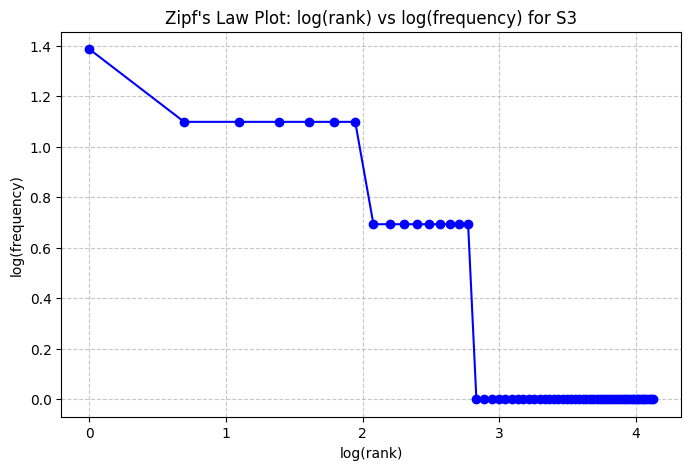


=== TOP 5 BIGRAMS IN S1 ===
('.', 'the'): 5
('.', 'i'): 4
('i', 'tried'): 3
('tried', 'restarting'): 3
('restarting', 'the'): 3

=== TOP 5 BIGRAMS IN S3 ===
('tried', 'restarting'): 3
('problem', 'occurs'): 3
('assignment', 'deadline'): 2
('failed', 'open'): 2
('restarting', 'matlab'): 1


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from nltk.stem import PorterStemmer
from nltk.util import bigrams

# 1. Construct the Subsets
# S1: all tokens from the original preprocessing
S1_tokens = []
S2_tokens = []
S3_tokens = []

for idx, row in df.iterrows():
    res = process_ticket(row['Ticket_Text'])
    S1_tokens.extend(res['tokens'])
    S2_tokens.extend([t for t in res['tokens'] if not is_punct(t)])
    S3_tokens.extend(res['final'])

# S4: S3 tokens after Porter Stemming
porter = PorterStemmer()
S4_tokens = [porter.stem(t) for t in S3_tokens]

# 2. Compute Statistics
def get_stats(tokens):
    tot = len(tokens)
    uniq = len(set(tokens))
    ttr = uniq / tot if tot > 0 else 0
    return tot, uniq, ttr

stats_records = []
for name, tokens in [("S1 (All Tokens)", S1_tokens),
                     ("S2 (No Punctuation)", S2_tokens),
                     ("S3 (Final Tokens)", S3_tokens),
                     ("S4 (S3 + Porter Stemmed)", S4_tokens)]:
    tot, uniq, ttr = get_stats(tokens)
    stats_records.append({
        "Subset": name,
        "Total Tokens": tot,
        "Unique Tokens": uniq,
        "TTR": round(ttr, 4)
    })

stats_df = pd.DataFrame(stats_records)
print("=== CORPUS STATISTICS ===")
display(stats_df)
print("\n")

# 3. Print top 10 words for S1 and S3
c_S1 = Counter(S1_tokens)
c_S3 = Counter(S3_tokens)
print("=== TOP 10 WORDS IN S1 ===")
print(c_S1.most_common(10))
print("\n=== TOP 10 WORDS IN S3 ===")
print(c_S3.most_common(10))
print("\n")

# 4. Plot log(rank) vs log(frequency) for S3
counts = sorted(list(c_S3.values()), reverse=True)
ranks = list(range(1, len(counts) + 1))

plt.figure(figsize=(8, 5))
plt.plot(np.log(ranks), np.log(counts), marker='o', linestyle='-', color='b')
plt.title("Zipf's Law Plot: log(rank) vs log(frequency) for S3")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# 5. Top 5 bigrams for S1 and S3
bi_S1 = list(bigrams(S1_tokens))
bi_S3 = list(bigrams(S3_tokens))

c_bi_S1 = Counter(bi_S1)
c_bi_S3 = Counter(bi_S3)

print("\n=== TOP 5 BIGRAMS IN S1 ===")
for bg, count in c_bi_S1.most_common(5):
    print(f"{bg}: {count}")

print("\n=== TOP 5 BIGRAMS IN S3 ===")
for bg, count in c_bi_S3.most_common(5):
    print(f"{bg}: {count}")


**Observe:** Why does TTR change from S1 to S4 in your data?

* **S1 to S2:** Removing punctuation slightly reduces both the total number of tokens and unique tokens, which maintains a similar Type-Token Ratio (TTR).
* **S2 to S3:** Stripping high-frequency, non-informative English stopwords dramatically reduces the total token count ($N$) while leaving the unique domain-specific vocabulary count relatively preserved. This drop in denominator causes the TTR to increase significantly.
* **S3 to S4:** Applying stemming collapses word variations (such as `failed` and `fails` into `fail`, or `restarting` to `restart`) down to their base forms. This reduces the number of unique tokens (types) while keeping the total token count identical, resulting in a decrease in the TTR.
